In [1]:
import numpy as np
import pandas as pd
df = pd.read_csv('loan_data.csv')
df

,Name,Income,Education,Gender,JobStability,LoanApproved
0,Mohan,3200.0,B.tech,Male,1.2,Yes
1,Andrea,3800.0,M.tech,Female,2.5,Yes
2,Joe,4100.0,B.tech,Male,0.8,No
3,Virat,4500.0,Phd,Male,3.6,Yes
4,Abdul,5200.0,M.tech,Male,2.1,Yes
5,Riya,6100.0,B.tech,Female,0.9,No
6,Sofia,NaN,Phd,Female,1.7,Yes
7,Elon Musk,10000000.0,Phd,Male,15.0,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Name          8 non-null      str    
 1   Income        7 non-null      float64
 2   Education     8 non-null      str    
 3   Gender        8 non-null      str    
 4   JobStability  8 non-null      float64
 5   LoanApproved  8 non-null      str    
dtypes: float64(2), str(4)
memory usage: 516.0 bytes


In [5]:
df.isnull().sum()

Name            0
Income          1
Education       0
Gender          0
JobStability    0
LoanApproved    0
dtype: int64

In [6]:
df_dropped = df.dropna()
df_dropped

,Name,Income,Education,Gender,JobStability,LoanApproved
0,Mohan,3200.0,B.tech,Male,1.2,Yes
1,Andrea,3800.0,M.tech,Female,2.5,Yes
2,Joe,4100.0,B.tech,Male,0.8,No
3,Virat,4500.0,Phd,Male,3.6,Yes
4,Abdul,5200.0,M.tech,Male,2.1,Yes
5,Riya,6100.0,B.tech,Female,0.9,No
7,Elon Musk,10000000.0,Phd,Male,15.0,Yes


In [7]:
df['Income'] = df['Income'].fillna(df['Income'].median())

In [8]:
q1 = df['Income'].quantile(0.25)
q3 = df['Income'].quantile(0.75)

In [9]:
iqr = q3-q1
iqr


np.float64(1400.0)

In [10]:
q1,q3

(np.float64(4025.0), np.float64(5425.0))

In [11]:
lower_limit = q3- 1.5*iqr
upper_limit = q3+ 1.5*iqr

df_clean = df[(df['Income']>lower_limit) & (df['Income']<upper_limit)]
df_clean

,Name,Income,Education,Gender,JobStability,LoanApproved
1,Andrea,3800.0,M.tech,Female,2.5,Yes
2,Joe,4100.0,B.tech,Male,0.8,No
3,Virat,4500.0,Phd,Male,3.6,Yes
4,Abdul,5200.0,M.tech,Male,2.1,Yes
5,Riya,6100.0,B.tech,Female,0.9,No
6,Sofia,4500.0,Phd,Female,1.7,Yes


In [12]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_clean['Education'] = le.fit_transform(df_clean['Education'])
df.head()

,Name,Income,Education,Gender,JobStability,LoanApproved
0,Mohan,3200.0,B.tech,Male,1.2,Yes
1,Andrea,3800.0,M.tech,Female,2.5,Yes
2,Joe,4100.0,B.tech,Male,0.8,No
3,Virat,4500.0,Phd,Male,3.6,Yes
4,Abdul,5200.0,M.tech,Male,2.1,Yes


In [13]:
# One-hot Encoding
df = pd.get_dummies(df, columns=['Gender'])
df.head()

,Name,Income,Education,JobStability,LoanApproved,Gender_Female,Gender_Male
0,Mohan,3200.0,B.tech,1.2,Yes,False,True
1,Andrea,3800.0,M.tech,2.5,Yes,True,False
2,Joe,4100.0,B.tech,0.8,No,False,True
3,Virat,4500.0,Phd,3.6,Yes,False,True
4,Abdul,5200.0,M.tech,2.1,Yes,False,True


In [16]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df['Income'] = scaler.fit_transform(df[['Income']])
df['JobStability'] = scaler.fit_transform(df[['JobStability']])
df.head()

,Name,Income,Education,JobStability,LoanApproved,Gender_Female,Gender_Male
0,Mohan,0.00000,B.tech,0.028169,Yes,False,True
1,Andrea,0.00006,M.tech,0.119718,Yes,True,False
2,Joe,0.00009,B.tech,0.000000,No,False,True
3,Virat,0.00013,Phd,0.197183,Yes,False,True
4,Abdul,0.00020,M.tech,0.091549,Yes,False,True


In [18]:
# Label Encode -> Loan Approved (1 Yes 2 No)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['LoanApproved'] = le.fit_transform(df[['LoanApproved']])
df.head()

/home/chaitu/Futurense/futurense_campus/python/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,Name,Income,Education,JobStability,LoanApproved,Gender_Female,Gender_Male
0,Mohan,0.00000,B.tech,0.028169,1,False,True
1,Andrea,0.00006,M.tech,0.119718,1,True,False
2,Joe,0.00009,B.tech,0.000000,0,False,True
3,Virat,0.00013,Phd,0.197183,1,False,True
4,Abdul,0.00020,M.tech,0.091549,1,False,True


In [19]:
# Scale education column
le = LabelEncoder()
df['Education'] = le.fit_transform(['Education'])
df.head()

ValueError: Columns must be same length as key

# Linear Regression

In [20]:
# Libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")                       # hide library notices
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
INK, ORANGE, TEAL, GREY = "#121821", "#C8471C", "#1D6963", "#9AA3AF"

In [22]:
# Helpers used all through the notebook

results = []                                            # one row per model we try

def record(name, actual, predicted):
    """Score a model on a slice and add it to the results table."""
    miss = np.abs(actual - predicted)
    row = {"model": name, "MAE ($)": round(miss.mean()), "mean miss (%)": float(round(100 * (miss / actual).mean(), 1))}
    results.append(row)
    print(row)

def coef_table(fit):
    """A statsmodels fit as a small table: coefficient, standard error, t, 95% interval."""
    ci = fit.conf_int()
    return pd.DataFrame({"coef": fit.params, "std err": fit.bse, "t": fit.tvalues,
                         "2.5%": ci[0], "97.5%": ci[1]}).round(2)

def vif_table(data, cols):
    """Variance inflation factor of each column, against the other columns."""
    X = sm.add_constant(data[cols]).values
    return pd.Series({c: round(variance_inflation_factor(X, i + 1), 2) for i, c in enumerate(cols)}, name="VIF")

## Load Data

In [21]:
houses = fetch_openml(name="house_prices", version=1, as_frame=True).frame   # download from OpenML
houses = houses.drop(columns="Id")                                             # an id carries no information

print(houses.shape)                                   # rows, columns
houses.head()

(1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Frame: what are we predicting, and when?

- **Target:** `SalePrice`, known only after the sale.
- **Inputs:** the columns a lender would have on listing day.
- **Measure:** MAE in dollars. The business reads it as "the typical miss".

In [ ]:

# Mean Absolute Error -> Average Error over the whole dataset
# Predicting - 50,000, MAE -> 200

# Prediciton will be in range of 50,000 +- 200

In [23]:

TARGET = "SalePrice"     # the column we predict


### 2.2 Column types

In [24]:

NUMBERS = houses.drop(columns=TARGET).select_dtypes("number").columns.tolist()   # number inputs
# Dropping the target column, selecting the numerical columns and converting to list
TEXT = houses.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()  # text inputs
ALL = NUMBERS + TEXT                                                              # every input

print(len(NUMBERS), "number inputs,", len(TEXT), "text inputs")

36 number inputs, 43 text inputs


In [25]:

TEXT

['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']


### 2.3 The target


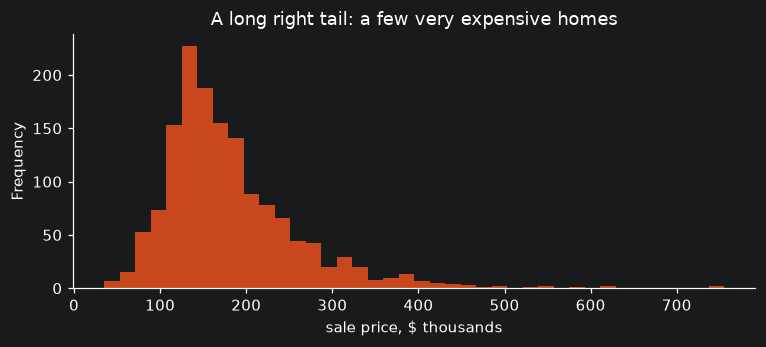

In [26]:
houses[TARGET].describe().round()

houses[TARGET].div(1000).plot.hist(bins=40, color=ORANGE, figsize=(8, 3))
plt.xlabel("sale price, $ thousands"); plt.title("A long right tail: a few very expensive homes")
plt.show()



### 2.4 Blanks per column



19 columns have blanks


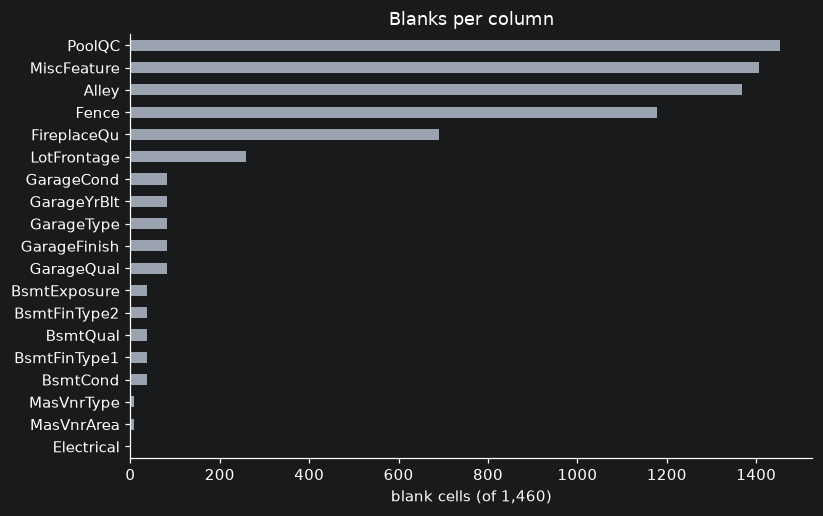

In [27]:
blanks = houses.isna().sum()
blanks = blanks[blanks > 0].sort_values()             # only columns with at least one blank
print(len(blanks), "columns have blanks")

blanks.plot.barh(color=GREY, figsize=(8, 5))
plt.xlabel("blank cells (of 1,460)"); plt.title("Blanks per column")
plt.show()

In [28]:
five = ["PoolQC", "GarageType", "FireplaceQu", "LotFrontage", "Electrical"]
print(houses[five].isna().sum())                  # blanks in each

PoolQC         1453
GarageType       81
FireplaceQu     690
LotFrontage     259
Electrical        1
dtype: int64


In [29]:
print(houses[five].describe(include="all").loc[["count", "top"]])   # what the filled values look like


      PoolQC GarageType FireplaceQu  LotFrontage Electrical
count      7       1379         770       1201.0       1459
top       Gd     Attchd          Gd          NaN      SBrkr


In [30]:
# Label each column: "by design" or "truly missing"
reason = {
    "PoolQC":      "by design",
    "GarageType":  "by design",
    "FireplaceQu": "by design",
    "LotFrontage": "truly missing",
    "Electrical":  "truly missing",
}
pd.Series(reason)

PoolQC             by design
GarageType         by design
FireplaceQu        by design
LotFrontage    truly missing
Electrical     truly missing
dtype: str

In [31]:

# Split the dataset Into 3 parts Train, test, validation

#Training -> train my model
# Validation -> ??
# Testing -> test my model before sending to real world

# Train, Test
# Some processes take very long to train
# To keep testing in between, we have this validation set
# Testing set will only be used ONCE at the final time.

rest, test = train_test_split(houses, test_size=0.20, random_state=42)   # seal the test slice
train, val = train_test_split(rest, test_size=0.25, random_state=42)     # split the rest

print(len(train), len(val), len(test))                                    # 876 292 292

876 292 292



## 5. Explore: train only

### 5.1 Which number columns move with price?

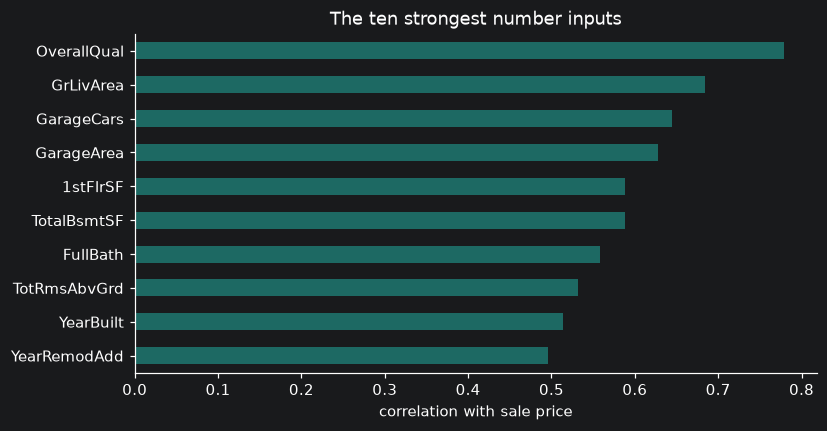

In [32]:

corr = train[NUMBERS].corrwith(train[TARGET]).sort_values()   # correlation of each number input with price

corr.tail(10).plot.barh(color=TEAL, figsize=(8, 4))
plt.xlabel("correlation with sale price"); plt.title("The ten strongest number inputs")
plt.show()


### 5.2 Living area against price

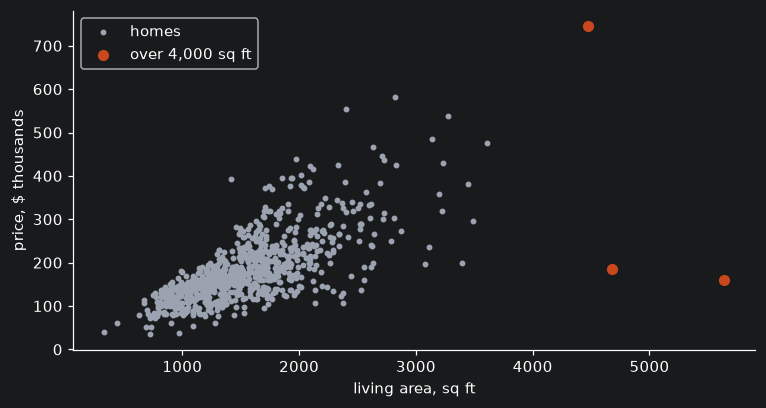

,GrLivArea,SalePrice,SaleCondition
523,4676,184750,Partial
1298,5642,160000,Partial
1182,4476,745000,Abnorml


In [33]:

big = train["GrLivArea"] > 4000                                # homes over 4,000 sq ft

plt.figure(figsize=(8, 4))
plt.scatter(train["GrLivArea"], train[TARGET] / 1000, s=8, color=GREY, label="homes")
plt.scatter(train.loc[big, "GrLivArea"], train.loc[big, TARGET] / 1000, s=40, color=ORANGE, label="over 4,000 sq ft")
plt.xlabel("living area, sq ft"); plt.ylabel("price, $ thousands"); plt.legend()
plt.show()

train.loc[big, ["GrLivArea", TARGET, "SaleCondition"]]


## 6. Prepare: one pipeline, fitted on train only

- Number blanks: the train median.
- Text blanks: the word "None", then one-hot encoding.
- Then a linear regression.

In [34]:

def make_model(cols):
    """Fill blanks, encode text, then fit a linear regression on the given columns."""
    nums = [c for c in cols if c in NUMBERS]
    txts = [c for c in cols if c in TEXT]
    prepare = make_column_transformer(
        (SimpleImputer(strategy="median"), nums),
        (make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                       OneHotEncoder(handle_unknown="ignore")), txts))
    return make_pipeline(prepare, LinearRegression())


### 7.2 All 79 inputs, through the pipeline

In [35]:

full = make_model(ALL).fit(train[ALL], train[TARGET])         # fit on train only
full_pred = full.predict(val[ALL])
record("All 79 columns", val[TARGET], full_pred)



{'model': 'All 79 columns', 'MAE ($)': 20308, 'mean miss (%)': 12.2}


In [36]:

plt.figure(figsize=(5, 5))
plt.scatter(test[TARGET] / 1000, test_pred / 1000, s=10, color=INK)
plt.plot([0, 800], [0, 800], color=ORANGE)                       # perfect predictions lie on this line
plt.xlabel("actual price, $ thousands"); plt.ylabel("predicted price, $ thousands")
plt.title("Test slice: 292 homes, scored once")
plt.show()

NameError: name 'test_pred' is not defined

<Figure size 550x550 with 0 Axes>

In [ ]:

# Improve the results, get better accuracy by applying other preprocessing steps
# Scaling
# Remove the irrelevant columns.